# CIFAR-10 KNN Classification

**Original Colab experiment with saved outputs.** This notebook compares K = 1, 3, 5, 7, 9 and Manhattan (L1) / Euclidean (L2) distances using the full CIFAR-10 train/test sets, 5-fold cross-validation, and Accuracy / macro Precision / macro Recall / macro F1.

CIFAR-10 is automatically downloaded to `/content/data` when run on Colab. For the saved results, the best model was **L1 with K=1**, and held-out test accuracy was **0.3859**.

## Dataset loading

In [1]:
from torchvision.datasets import CIFAR10

# 학습 데이터 다운로드
train_dataset = CIFAR10(
    root="/content/data",
    train=True,
    download=True
)

# 테스트 데이터 다운로드
test_dataset = CIFAR10(
    root="/content/data",
    train=False,
    download=True
)

print("Training:", len(train_dataset))
print("Test:", len(test_dataset))

100%|██████████| 170M/170M [50:54<00:00, 55.8kB/s]


Training: 50000
Test: 10000


## Experiment settings

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torchvision.datasets import CIFAR10
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 실험 설정
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 사용할 이미지 수
TRAIN_SIZE = 50000
TEST_SIZE = 10000

# 비교할 K 값과 거리 측정 방법
k_values = [1, 3, 5, 7, 9]
distance_metrics = ["L1", "L2"]

# GPU가 있으면 사용하고, 없으면 CPU 사용
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


Device: cuda


In [3]:

# CIFAR-10 다운로드
train_dataset = CIFAR10(
    root="/content/data",
    train=True,
    download=True
)

test_dataset = CIFAR10(
    root="/content/data",
    train=False,
    download=True
)

print("전체 학습 데이터:", len(train_dataset))
print("전체 테스트 데이터:", len(test_dataset))
print("클래스:", train_dataset.classes)


전체 학습 데이터: 50000
전체 테스트 데이터: 10000
클래스: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Full CIFAR-10 preprocessing

In [4]:

# CIFAR-10 전체 데이터 사용
# Train: 50,000장 / Test: 10,000장

# 이미지 평탄화 및 정규화
X_train = train_dataset.data.reshape(50000, -1)
X_train = X_train.astype(np.float32) / 255.0

X_test = test_dataset.data.reshape(10000, -1)
X_test = X_test.astype(np.float32) / 255.0

# 라벨
y_train = np.array(train_dataset.targets)
y_test = np.array(test_dataset.targets)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("Training class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))


X_train: (50000, 3072)
y_train: (50000,)
X_test : (10000, 3072)
y_test : (10000,)
Training class counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Test class counts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## KNN implementation

In [5]:

# 가장 가까운 이웃들의 인덱스를 구하는 함수
def find_nearest_neighbors(
    train_images, query_images,
    metric="L2", max_k=9, batch_size=64
):
    # L1: Manhattan, L2: Euclidean
    p = 1 if metric == "L1" else 2

    train_tensor = torch.from_numpy(train_images).to(device)
    query_tensor = torch.from_numpy(query_images).to(device)

    all_neighbors = []

    with torch.no_grad():
        # 메모리 사용량을 줄이기 위해 나누어 계산
        for start in range(0, len(query_tensor), batch_size):
            query_batch = query_tensor[start:start + batch_size]

            # 학습 이미지와의 거리 계산
            distances = torch.cdist(query_batch, train_tensor, p=p)

            # 가장 가까운 max_k개 선택
            nearest = torch.topk(
                distances,
                k=max_k,
                dim=1,
                largest=False,
                sorted=True
            ).indices

            all_neighbors.append(nearest.cpu().numpy())

    return np.concatenate(all_neighbors, axis=0)


# 선택한 K개 이웃의 다수결로 예측
def predict_knn(neighbor_indices, train_labels, k):
    predictions = []

    for indices in neighbor_indices:
        labels = train_labels[indices[:k]]

        # 각 클래스가 몇 번 등장했는지 계산
        counts = np.bincount(labels, minlength=10)

        # 가장 많이 등장한 클래스 선택
        predicted_class = np.argmax(counts)
        predictions.append(predicted_class)

    return np.array(predictions)


## Evaluation metrics

In [6]:

def get_scores(y_true, y_pred):
    scores = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    return scores


## Stratified 5-fold cross-validation

In [7]:

# 5-fold Cross-Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

results = []

for fold, (train_ids, val_ids) in enumerate(
    skf.split(X_train, y_train), start=1
):
    X_tr = X_train[train_ids]
    X_val = X_train[val_ids]

    y_tr = y_train[train_ids]
    y_val = y_train[val_ids]

    print(f"\nFold {fold}/5")

    for metric in distance_metrics:

        # 가장 가까운 9개 이웃을 한 번 계산
        neighbors = find_nearest_neighbors(
            X_tr,
            X_val,
            metric=metric,
            max_k=max(k_values)
        )

        for k in k_values:
            # K개의 이웃으로 예측
            y_pred = predict_knn(neighbors, y_tr, k)

            # 평가 지표 계산
            scores = get_scores(y_val, y_pred)

            results.append({
                "fold": fold,
                "metric": metric,
                "k": k,
                **scores
            })

            print(
                f"{metric}, K={k}: "
                f"Accuracy={scores['accuracy']:.4f}, "
                f"F1={scores['f1']:.4f}"
            )

# 결과를 DataFrame으로 정리
cv_results = pd.DataFrame(results)

print("\nCross-Validation 완료")
print("총 실험 결과 수:", len(cv_results))

display(cv_results.head(10))



Fold 1/5
L1, K=1: Accuracy=0.3676, F1=0.3653
L1, K=3: Accuracy=0.3526, F1=0.3475
L1, K=5: Accuracy=0.3601, F1=0.3541
L1, K=7: Accuracy=0.3619, F1=0.3560
L1, K=9: Accuracy=0.3682, F1=0.3628
L2, K=1: Accuracy=0.3379, F1=0.3326
L2, K=3: Accuracy=0.3214, F1=0.3089
L2, K=5: Accuracy=0.3331, F1=0.3209
L2, K=7: Accuracy=0.3297, F1=0.3178
L2, K=9: Accuracy=0.3348, F1=0.3203

Fold 2/5
L1, K=1: Accuracy=0.3726, F1=0.3706
L1, K=3: Accuracy=0.3626, F1=0.3587
L1, K=5: Accuracy=0.3708, F1=0.3633
L1, K=7: Accuracy=0.3711, F1=0.3645
L1, K=9: Accuracy=0.3680, F1=0.3603
L2, K=1: Accuracy=0.3399, F1=0.3334
L2, K=3: Accuracy=0.3283, F1=0.3146
L2, K=5: Accuracy=0.3363, F1=0.3214
L2, K=7: Accuracy=0.3340, F1=0.3184
L2, K=9: Accuracy=0.3358, F1=0.3196

Fold 3/5
L1, K=1: Accuracy=0.3707, F1=0.3700
L1, K=3: Accuracy=0.3627, F1=0.3581
L1, K=5: Accuracy=0.3636, F1=0.3591
L1, K=7: Accuracy=0.3610, F1=0.3558
L1, K=9: Accuracy=0.3607, F1=0.3550
L2, K=1: Accuracy=0.3422, F1=0.3374
L2, K=3: Accuracy=0.3223, F1=0.312

,fold,metric,k,accuracy,precision,recall,f1
0,1,L1,1,0.3676,0.411659,0.3676,0.365259
1,1,L1,3,0.3526,0.439233,0.3526,0.347536
2,1,L1,5,0.3601,0.435333,0.3601,0.354056
3,1,L1,7,0.3619,0.444765,0.3619,0.356037
4,1,L1,9,0.3682,0.453002,0.3682,0.362835
5,1,L2,1,0.3379,0.395412,0.3379,0.332628
6,1,L2,3,0.3214,0.413108,0.3214,0.308921
7,1,L2,5,0.3331,0.426241,0.3331,0.320933
8,1,L2,7,0.3297,0.434956,0.3297,0.317828
9,1,L2,9,0.3348,0.444334,0.3348,0.320256


## Cross-validation comparison and model selection

In [8]:

# Fold별 평가 결과의 평균과 표준편차 계산
cv_summary = cv_results.groupby(
    ["metric", "k"], as_index=False
).agg(
    cv_accuracy=("accuracy", "mean"),
    cv_accuracy_std=("accuracy", "std"),
    cv_precision=("precision", "mean"),
    cv_recall=("recall", "mean"),
    cv_f1=("f1", "mean")
)

# Accuracy 기준 정렬 (동점이면 F1 사용)
cv_summary = cv_summary.sort_values(
    ["cv_accuracy", "cv_f1"],
    ascending=False
).reset_index(drop=True)

print("K 값과 Distance Metric별 비교")
display(cv_summary.round(4))

# 가장 좋은 조합 선택
best_metric = cv_summary.loc[0, "metric"]
best_k = int(cv_summary.loc[0, "k"])

print("\nBest Distance Metric:", best_metric)
print("Best K:", best_k)
print("CV Accuracy:", round(cv_summary.loc[0, "cv_accuracy"], 4))
print("CV F1:", round(cv_summary.loc[0, "cv_f1"], 4))


K 값과 Distance Metric별 비교


,metric,k,cv_accuracy,cv_accuracy_std,cv_precision,cv_recall,cv_f1
0,L1,1,0.3708,0.0019,0.4164,0.3708,0.3690
1,L1,5,0.3630,0.0046,0.4411,0.3630,0.3562
2,L1,9,0.3628,0.0052,0.4488,0.3628,0.3551
3,L1,7,0.3628,0.0053,0.4481,0.3628,0.3560
4,L1,3,0.3559,0.0065,0.4457,0.3559,0.3510
5,L2,1,0.3405,0.0020,0.3971,0.3405,0.3346
6,L2,9,0.3335,0.0023,0.4413,0.3335,0.3177
7,L2,5,0.3327,0.0025,0.4264,0.3327,0.3185
8,L2,7,0.3315,0.0025,0.4352,0.3315,0.3166
9,L2,3,0.3235,0.0027,0.4231,0.3235,0.3111



Best Distance Metric: L1
Best K: 1
CV Accuracy: 0.3708
CV F1: 0.369


## Accuracy and F1 comparison plots

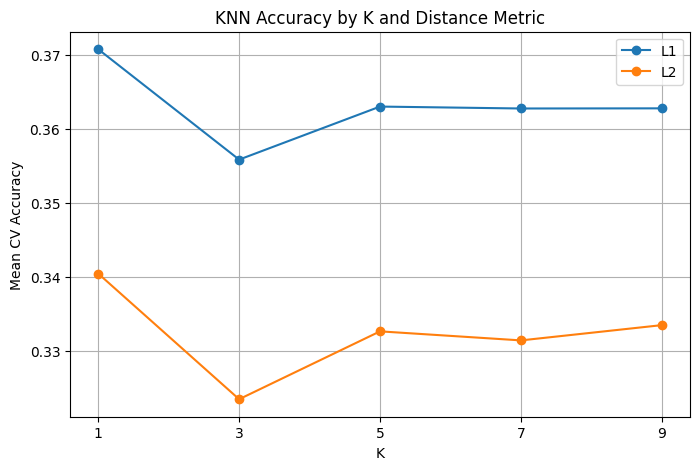

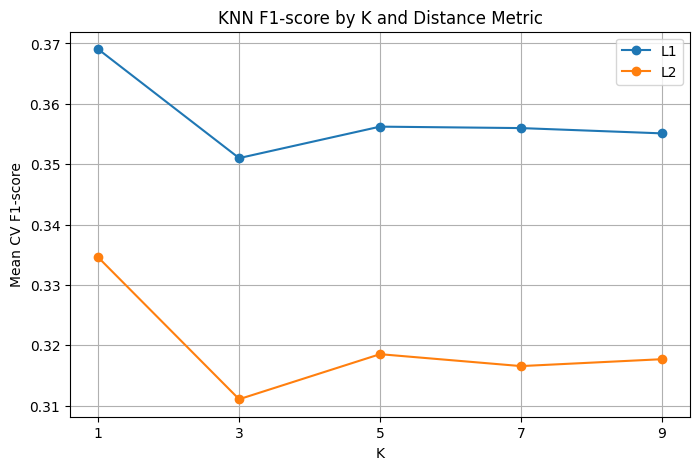

In [9]:

# K 값에 따른 Accuracy 변화
plt.figure(figsize=(8, 5))

for metric in distance_metrics:
    data = cv_summary[cv_summary["metric"] == metric]
    data = data.sort_values("k")

    plt.plot(
        data["k"],
        data["cv_accuracy"],
        marker="o",
        label=metric
    )

plt.title("KNN Accuracy by K and Distance Metric")
plt.xlabel("K")
plt.ylabel("Mean CV Accuracy")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()


# K 값에 따른 F1-score 변화
plt.figure(figsize=(8, 5))

for metric in distance_metrics:
    data = cv_summary[cv_summary["metric"] == metric]
    data = data.sort_values("k")

    plt.plot(
        data["k"],
        data["cv_f1"],
        marker="o",
        label=metric
    )

plt.title("KNN F1-score by K and Distance Metric")
plt.xlabel("K")
plt.ylabel("Mean CV F1-score")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()


## Final held-out test evaluation

In [10]:

# 전체 선택 학습 데이터로 최종 KNN 예측
test_neighbors = find_nearest_neighbors(
    X_train,
    X_test,
    metric=best_metric,
    max_k=best_k
)

test_pred = predict_knn(
    test_neighbors,
    y_train,
    best_k
)

# 최종 평가
test_scores = get_scores(y_test, test_pred)

print("Final Test Results")
print("-----------------------------")
print("Distance Metric:", best_metric)
print("K:", best_k)
print("Accuracy :", round(test_scores["accuracy"], 4))
print("Precision:", round(test_scores["precision"], 4))
print("Recall   :", round(test_scores["recall"], 4))
print("F1-score :", round(test_scores["f1"], 4))

# 클래스별 평가 결과
print("\nClassification Report")
print(classification_report(
    y_test,
    test_pred,
    target_names=train_dataset.classes,
    zero_division=0
))


Final Test Results
-----------------------------
Distance Metric: L1
K: 1
Accuracy : 0.3859
Precision: 0.4333
Recall   : 0.3859
F1-score : 0.3862

Classification Report
              precision    recall  f1-score   support

    airplane       0.42      0.52      0.47      1000
  automobile       0.66      0.30      0.41      1000
        bird       0.26      0.41      0.32      1000
         cat       0.30      0.26      0.28      1000
        deer       0.27      0.45      0.34      1000
         dog       0.39      0.31      0.34      1000
        frog       0.37      0.37      0.37      1000
       horse       0.58      0.34      0.43      1000
        ship       0.45      0.62      0.52      1000
       truck       0.63      0.28      0.38      1000

    accuracy                           0.39     10000
   macro avg       0.43      0.39      0.39     10000
weighted avg       0.43      0.39      0.39     10000



## Confusion matrix

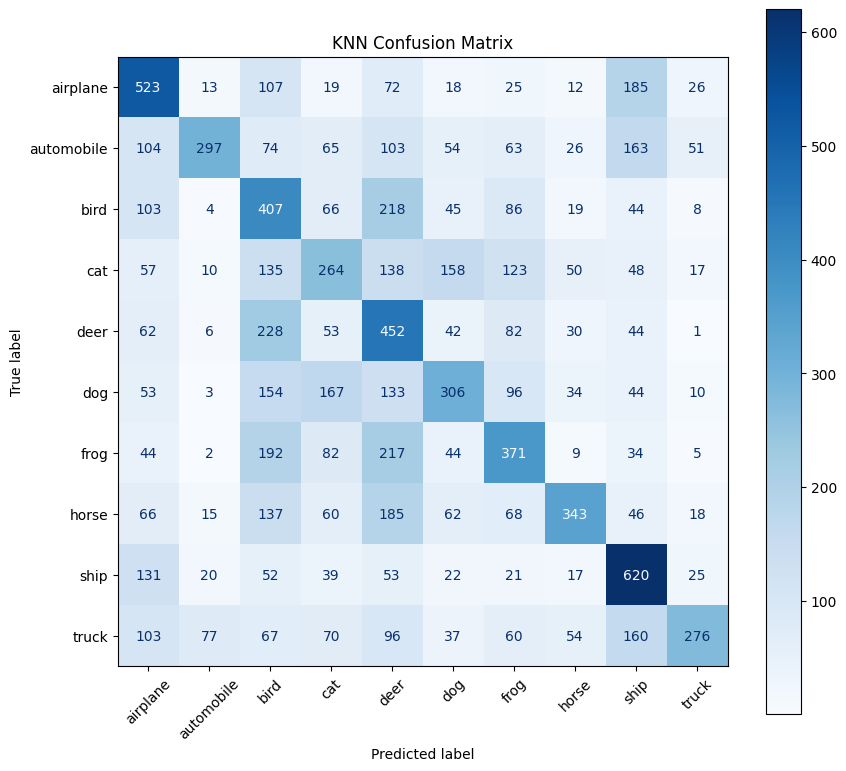

In [11]:

fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=train_dataset.classes,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()
